# 00 · Project summary: cost-aware fraud detection on one page

This notebook reads the committed results of notebooks 01–06 (`reports/`) and summarises the
project: **problem → data and limits → results with uncertainty → business decision → what did
not work**. It computes nothing new; every number below is pulled from those artifacts by
`fraud_e2e.summary.build_context()`.

In [1]:
from IPython.display import Image, Markdown, display

from fraud_e2e import config as C
from fraud_e2e.summary import build_context

c = build_context()


def fig(name: str, width: int = 820):
    display(Image(filename=str(C.FIGURES_DIR / f"{name}.png"), width=width))

In [2]:
display(
    Markdown(f"""
## 1. The problem

A card issuer scores every transaction. Scores above a threshold go to **step-up** (review or extra
authentication); the rest are approved. Two mistakes cost money differently: a good customer stepped
up (friction) and a missed fraud (the amount is lost). We want a model that **ranks** fraud well and
a **threshold** that minimises total expected cost.

## 2. Data and its limits

- *Credit Card Fraud Detection 2026* (Udit Jain, Kaggle, **CC0**), a **public dataset of unspecified
  provenance**: {c["n_rows"]} transactions, {c["n_fraud"]} fraud ({c["fraud_rate"]}, 95% CI
  {c["fraud_rate_ci"]}), {c["n_features"]} features. {c["n_checks_failed"]} of {c["n_checks"]}
  structural checks failed.
- Hints of synthetic generation: channel and device look independent (p = {c["chan_dev_p"]}); the
  smallest fraud is {c["fraud_min_usd"]}. Results describe this dataset only.
- No customer/card ID, no real timestamp → no customer features, no out-of-time test.
- Locked split before any label-based analysis: dev {c["dev_n"]} rows / {c["dev_fraud"]} fraud
  (5-fold CV × 3 repeats); holdout {c["holdout_n"]} rows / {c["holdout_fraud"]} fraud, scored **once**.
""")
)


## 1. The problem

A card issuer scores every transaction. Scores above a threshold go to **step-up** (review or extra
authentication); the rest are approved. Two mistakes cost money differently: a good customer stepped
up (friction) and a missed fraud (the amount is lost). We want a model that **ranks** fraud well and
a **threshold** that minimises total expected cost.

## 2. Data and its limits

- *Credit Card Fraud Detection 2026* (Udit Jain, Kaggle, **CC0**), a **public dataset of unspecified
  provenance**: 20,000 transactions, 339 fraud (1.70%, 95% CI
  [1.53%, 1.88%]), 24 features. 0 of 26
  structural checks failed.
- Hints of synthetic generation: channel and device look independent (p = 0.44); the
  smallest fraud is 5.14 USD. Results describe this dataset only.
- No customer/card ID, no real timestamp → no customer features, no out-of-time test.
- Locked split before any label-based analysis: dev 16,000 rows / 271 fraud
  (5-fold CV × 3 repeats); holdout 4,000 rows / 68 fraud, scored **once**.



## 3. Main results

Final model: **logistic regression**. A random score has PR-AUC ≈ 0.0169 (the fraud rate).

| Metric | CV on dev (mean [95% CI]) | Holdout, once [bootstrap 95% CI] |
|---|---|---|
| PR-AUC (primary) | 0.415 [0.341, 0.490] | 0.468 [0.361, 0.585] |
| ROC-AUC | 0.942 [0.928, 0.957] | 0.950 [0.923, 0.972] |
| Recall at threshold 0.0695 | 69.5% | 70.6% [60.3%, 80.9%] |
| Precision at threshold | 23.5% | 23.8% [20.0%, 27.8%] |
| Share stepped up | 5.01% | 5.05% [4.45%, 5.67%] |

The holdout agrees with CV within its (wide) intervals. Logistic regression beat the best gradient
boosting pipeline (`lgbm_tuned`, PR-AUC 0.367): difference
-0.048 [-0.084, -0.012], boosting minus logistic. On this dataset fraud odds
multiply with each red flag (×7.6, ×5.7, ×4.9, ×3.2 per extra flag), the additive log-odds
shape a logistic model represents directly.


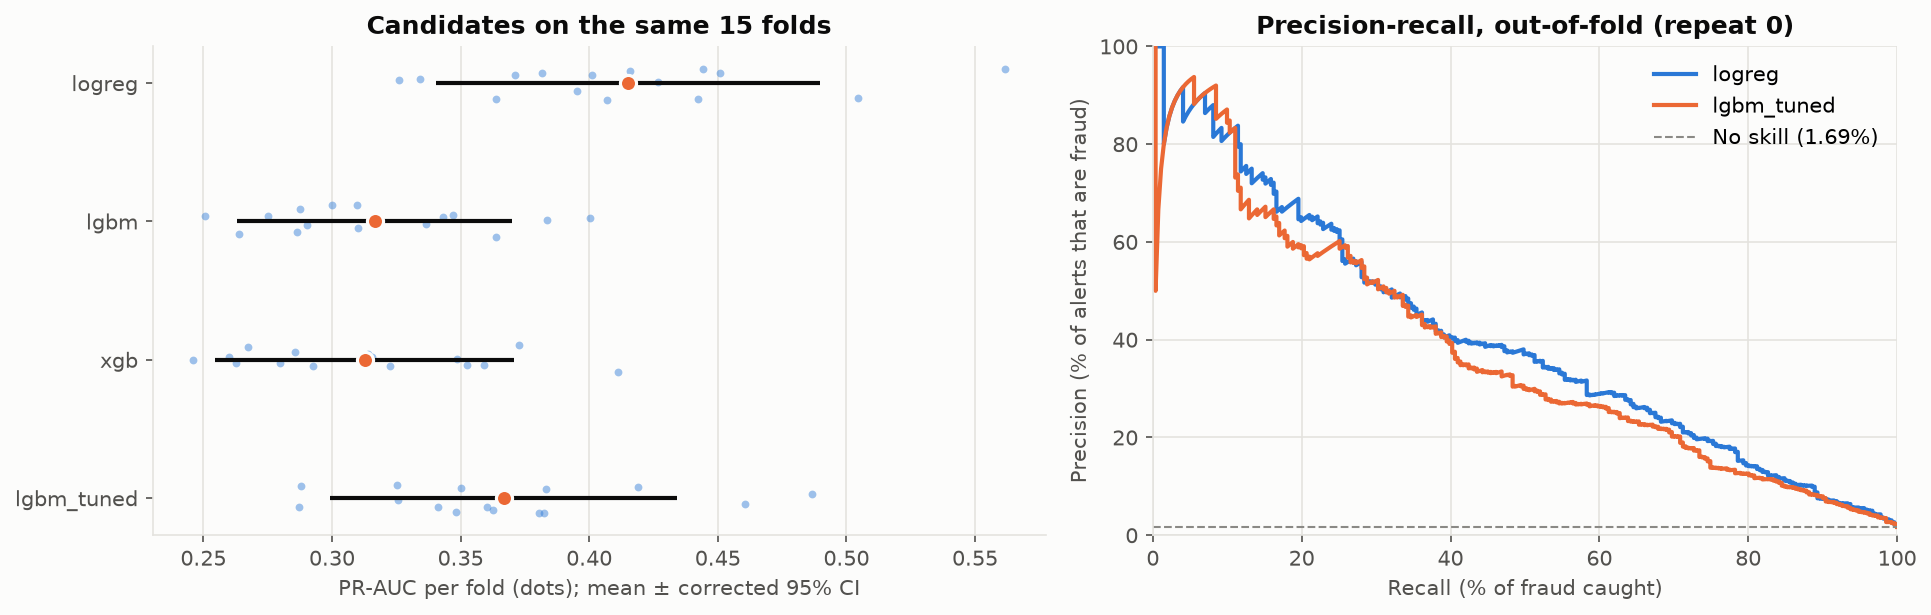

In [3]:
display(
    Markdown(f"""
## 3. Main results

Final model: **{c["final_model"]}**. A random score has PR-AUC ≈ {c["noskill"]} (the fraud rate).

| Metric | CV on dev (mean [95% CI]) | Holdout, once [bootstrap 95% CI] |
|---|---|---|
| PR-AUC (primary) | {c["cv_pr_auc"]} {c["cv_pr_auc_ci"]} | {c["ho_pr_auc"]} {c["ho_pr_auc_ci"]} |
| ROC-AUC | {c["cv_roc_auc"]} {c["cv_roc_auc_ci"]} | {c["ho_roc_auc"]} {c["ho_roc_auc_ci"]} |
| Recall at threshold {c["threshold"]} | {c["cv_recall"]} | {c["ho_recall"]} {c["ho_recall_ci"]} |
| Precision at threshold | {c["cv_precision"]} | {c["ho_precision"]} {c["ho_precision_ci"]} |
| Share stepped up | {c["cv_alert_rate"]} | {c["ho_alert_rate"]} {c["ho_alert_rate_ci"]} |

The holdout agrees with CV within its (wide) intervals. Logistic regression beat the best gradient
boosting pipeline (`{c["best_boost_name"]}`, PR-AUC {c["best_boost_pr_auc"]}): difference
{c["boost_vs_lr_diff"]} {c["boost_vs_lr_ci"]}, boosting minus logistic. On this dataset fraud odds
multiply with each red flag ({c["flag_odds_multipliers"]} per extra flag), the additive log-odds
shape a logistic model represents directly.
""")
)
fig("p2_model_comparison")


## 4. The business decision

**Illustrative assumed costs (not bank data):** step-up 5 USD; extra friction for a good customer
10 USD; a missed fraud costs its amount + 15 USD.

- Step up every transaction scoring ≥ **0.0695** (chosen on dev out-of-fold predictions;
  per-repeat optimum 0.0673–0.0834).
- On CV this catches 69.5% of fraud while stepping up 5.01% of traffic
  (about 4.3 step-ups per fraud found), cutting expected cost by 47.6%
  vs doing nothing (1,664 USD vs 3,175 USD per 1,000 transactions).
  On the holdout the saving was 37.0% [13.2%, 63.4%] (post-hoc, descriptive).
- The threshold depends on the costs: scaling each cost ×0.5 or ×2 moves it between
  0.0292 and 0.1334. With real costs, re-derive it.


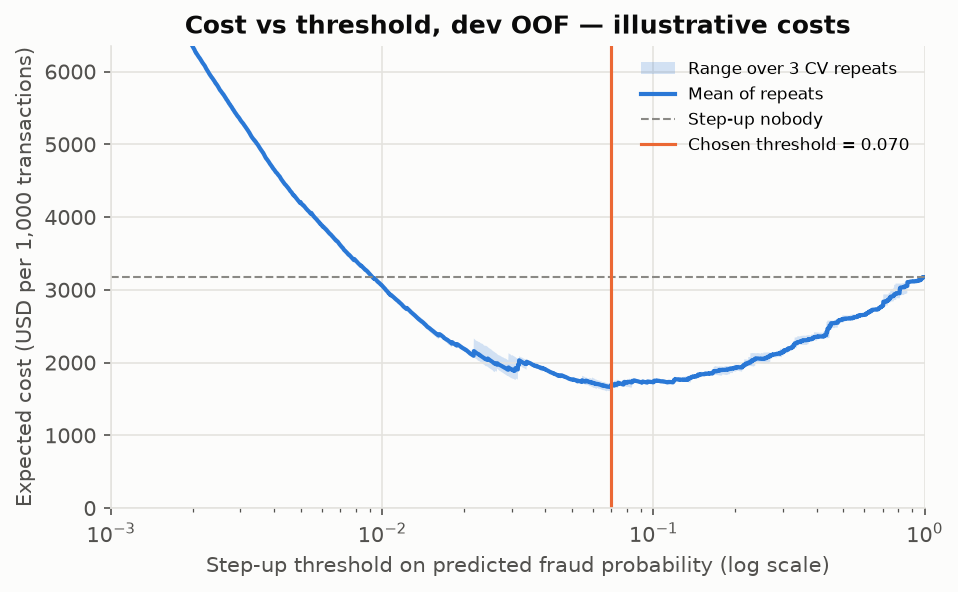

In [4]:
display(
    Markdown(f"""
## 4. The business decision

**{c["cost_label"]}:** step-up {c["cost_review"]} USD; extra friction for a good customer
{c["cost_friction"]} USD; a missed fraud costs its amount + {c["cost_fn_fixed"]} USD.

- Step up every transaction scoring ≥ **{c["threshold"]}** (chosen on dev out-of-fold predictions;
  per-repeat optimum {c["thr_repeat_range"]}).
- On CV this catches {c["cv_recall"]} of fraud while stepping up {c["cv_alert_rate"]} of traffic
  (about {c["alerts_per_fraud"]} step-ups per fraud found), cutting expected cost by {c["cv_saving"]}
  vs doing nothing ({c["cv_cost_per_1000"]} vs {c["cv_nothing_per_1000"]} per 1,000 transactions).
  On the holdout the saving was {c["ho_saving"]} {c["ho_saving_ci"]} (post-hoc, descriptive).
- The threshold depends on the costs: scaling each cost ×0.5 or ×2 moves it between
  {c["sens_thr_min"]} and {c["sens_thr_max"]}. With real costs, re-derive it.
""")
)
fig("p2_cost_curve", 640)


## 5. What did not work (and why that is useful)

- **SMOTE:** PR-AUC -0.177 [-0.229, -0.125] vs no resampling. SMOTENC fills
  categorical/boolean features by neighbour majority vote, so synthetic fraud carried red flags only
  0.38× as often as real fraud (e.g. IP-country mismatch 31%
  real vs 18% synthetic).
- **Class weights / undersampling:** -0.023 [-0.058, +0.013] and -0.005 [-0.036, +0.026],
  not distinguishable from doing nothing; weighting also distorted probabilities.
- **Gradient boosting:** tuning helped LightGBM (+0.050 [+0.014, +0.086]) and pushed it
  to tiny trees, but it still trailed logistic regression.
- **Calibration:** neither sigmoid nor isotonic calibration improved the Brier score.
- **Three-tier policy (add "decline"):** cheaper on CV (-104 USD per 1,000) but not
  distinguishable on the holdout: -21 USD [-103, +60]. The simpler two-tier policy is recommended.


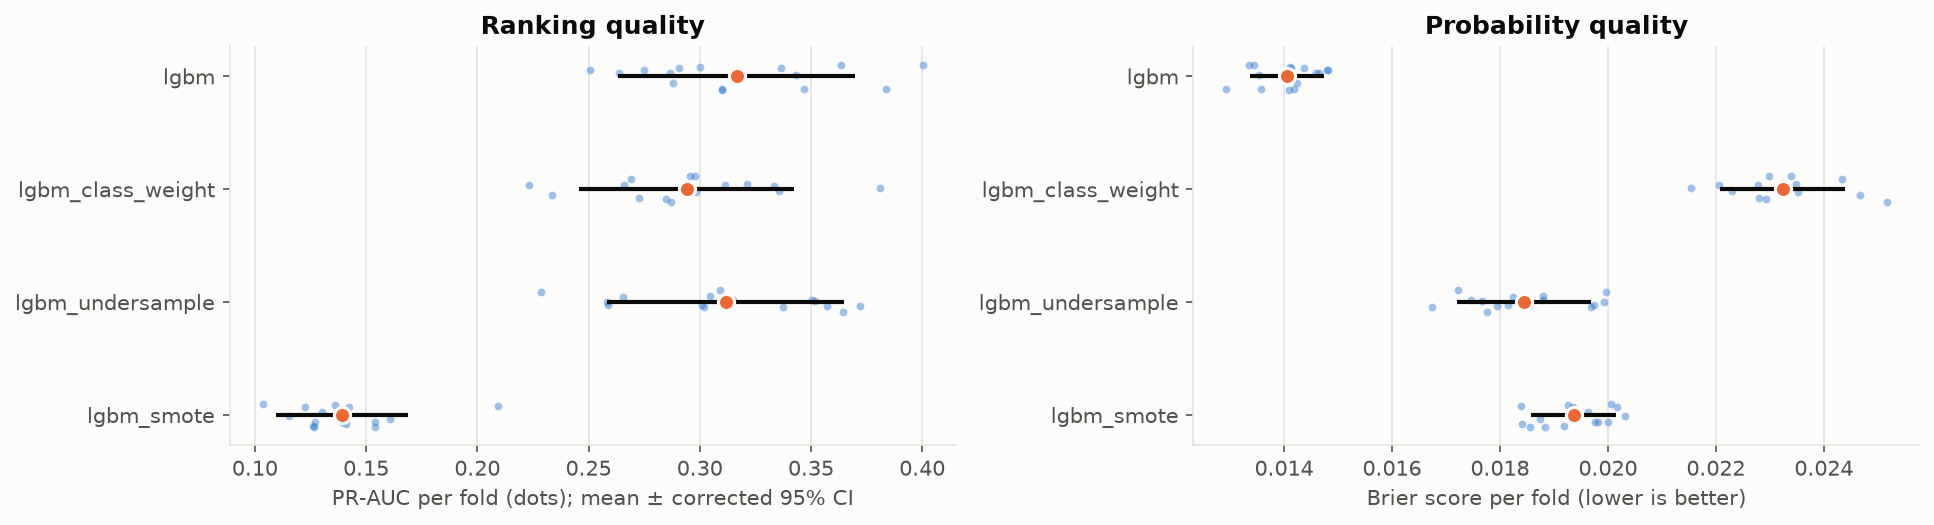

In [5]:
display(
    Markdown(f"""
## 5. What did not work (and why that is useful)

- **SMOTE:** PR-AUC {c["smote_diff"]} {c["smote_ci"]} vs no resampling. SMOTENC fills
  categorical/boolean features by neighbour majority vote, so synthetic fraud carried red flags only
  {c["smote_flag_ratio"]}× as often as real fraud (e.g. IP-country mismatch {c["smote_ipmis_real"]}
  real vs {c["smote_ipmis_syn"]} synthetic).
- **Class weights / undersampling:** {c["cw_diff"]} {c["cw_ci"]} and {c["us_diff"]} {c["us_ci"]},
  not distinguishable from doing nothing; weighting also distorted probabilities.
- **Gradient boosting:** tuning helped LightGBM ({c["tuning_diff"]} {c["tuning_ci"]}) and pushed it
  to tiny trees, but it still trailed logistic regression.
- **Calibration:** {c["calibration_verdict"]}.
- **Three-tier policy (add "decline"):** cheaper on CV ({c["tt_cv_diff"]} per 1,000) but not
  distinguishable on the holdout: {c["ho_tt_diff"]} {c["ho_tt_diff_ci"]}. The simpler two-tier policy is recommended.
""")
)
fig("p2_imbalance_folds")


## 6. What drives the score

Top drivers by mean |SHAP|: `merchant_risk_score`, `velocity_score`, `cvv_retry_count` (37% of the total). A false alarm
and a caught fraud can carry the same red flags; separating them more likely needs information this
dataset does not have (customer history) than a different algorithm.


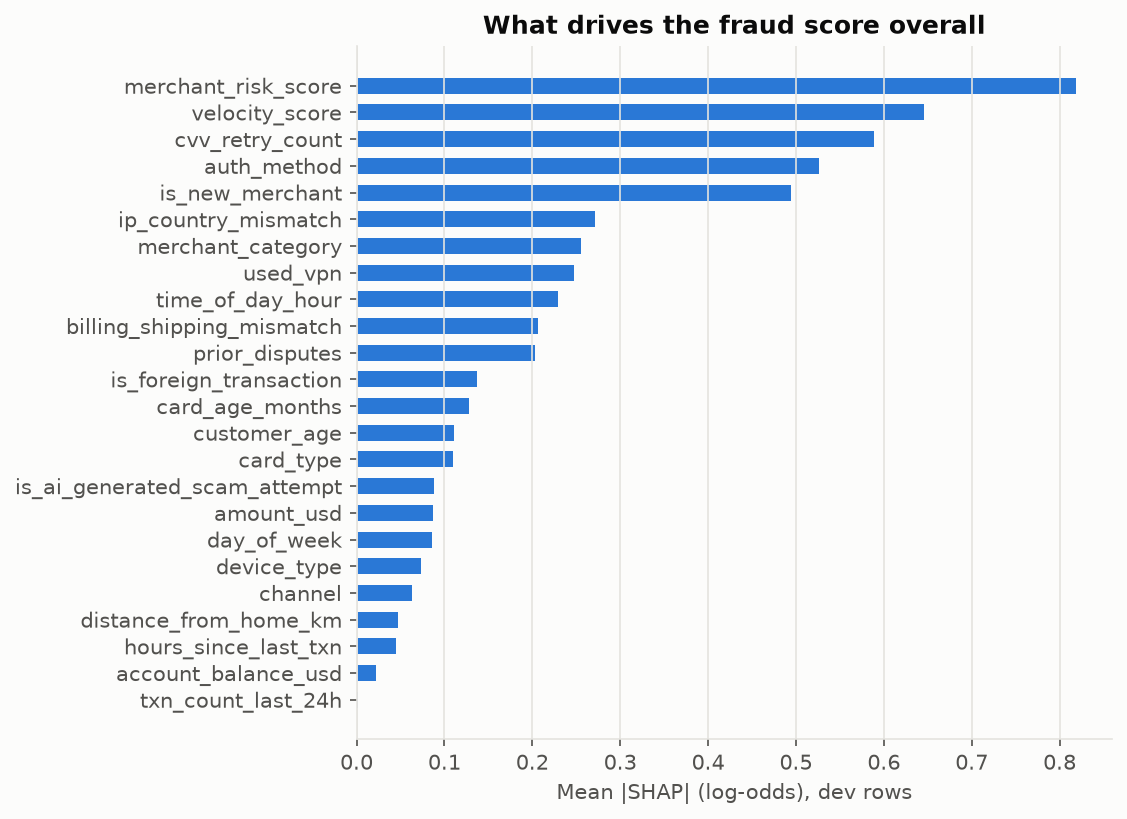

In [6]:
display(
    Markdown(f"""
## 6. What drives the score

Top drivers by mean |SHAP|: {c["shap_top3"]} ({c["shap_top3_share"]} of the total). A false alarm
and a caught fraud can carry the same red flags; separating them more likely needs information this
dataset does not have (customer history) than a different algorithm.
""")
)
fig("p2_shap_global", 520)

In [7]:
display(
    Markdown("""
## 7. Where to look next

- Method and decision rules: `notes/00_preregistration.md` (with dated amendments A1–A4).
- Full results: notebooks 01–06; model card: `docs/model_card.md`.
- Deferred: API / Docker / MLflow / CI and drift monitoring.
""")
)


## 7. Where to look next

- Method and decision rules: `notes/00_preregistration.md` (with dated amendments A1–A4).
- Full results: notebooks 01–06; model card: `docs/model_card.md`.
- Deferred: API / Docker / MLflow / CI and drift monitoring.
